In [3]:
# ==========================================
# CUSTOMER SEGMENTATION USING K-MEANS
# PHASE 1: LIBRARY IMPORTS
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Model evaluation
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score

# Model saving
import joblib

# Utility libraries
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded))

# Load dataset
df = pd.read_csv(filename)

# Standardize column names
df = df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "Income",
    "Spending Score (1-100)": "SpendingScore"
})

print("Dataset loaded successfully!")
display(df.head())

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!


,CustomerID,Gender,Age,Income,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Income', 'SpendingScore']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     200 non-null    int64 
 1   Gender         200 non-null    object
 2   Age            200 non-null    int64 
 3   Income         200 non-null    int64 
 4   SpendingScore  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Statistical Summary:


,CustomerID,Gender,Age,Income,SpendingScore
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate Customer IDs:",
      df["CustomerID"].duplicated().sum())

print("\nGender Distribution:")
print(df["Gender"].value_counts())

print("\nData Types:")
print(df.dtypes)

Missing Values:
CustomerID       0
Gender           0
Age              0
Income           0
SpendingScore    0
dtype: int64

Duplicate Rows: 0

Duplicate Customer IDs: 0

Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64

Data Types:
CustomerID        int64
Gender           object
Age               int64
Income            int64
SpendingScore     int64
dtype: object


In [7]:
import hashlib

with open(filename, "rb") as file:
    dataset_hash = hashlib.sha256(file.read()).hexdigest()

print("Dataset SHA256:", dataset_hash)

Dataset SHA256: 416a4f62a8f33841a16e1db5297f0e05d3b65b05e73632cedae58e739e1e1f77


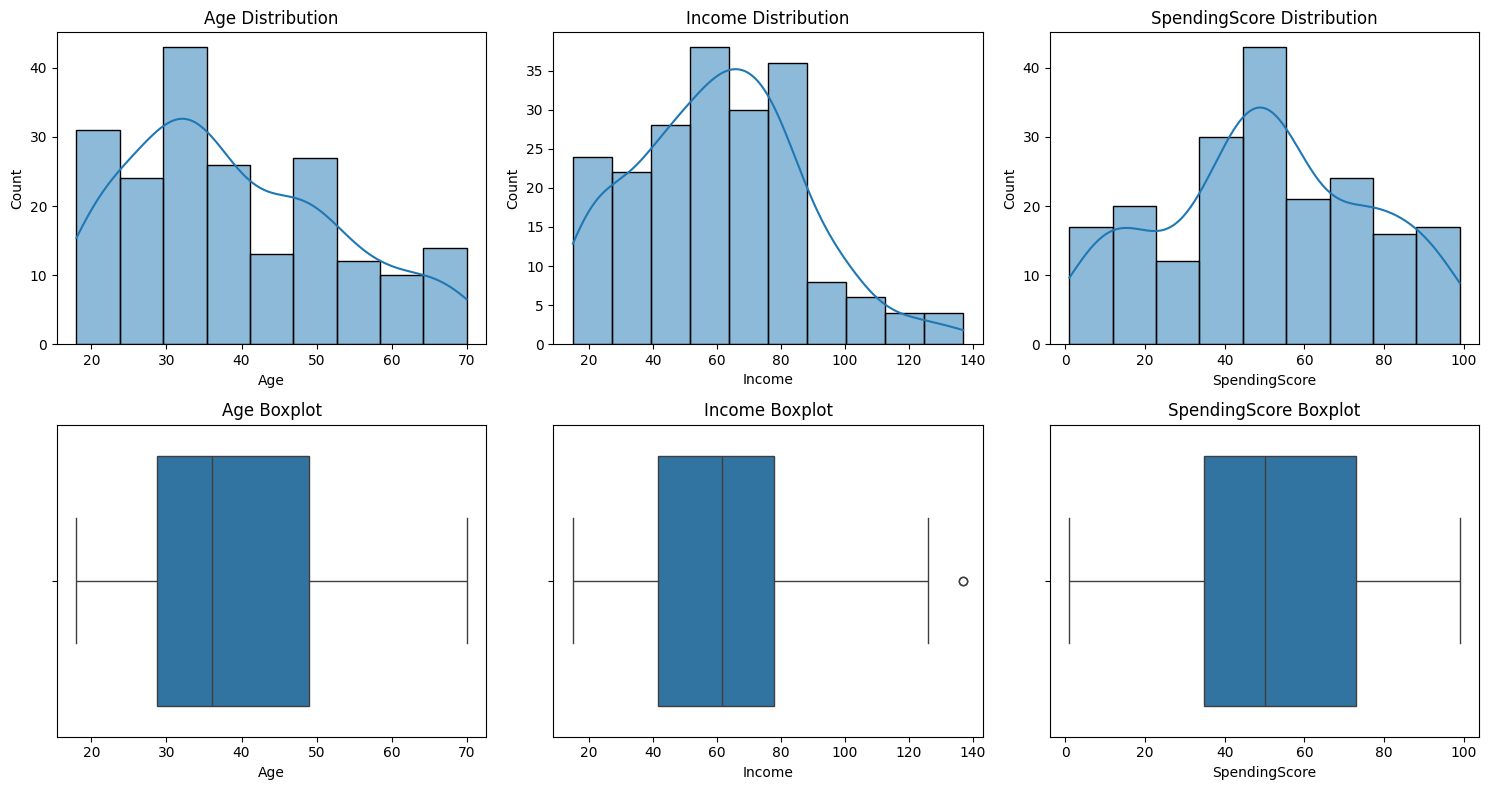

In [8]:
numeric_features = [
    "Age",
    "Income",
    "SpendingScore"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, feature in enumerate(numeric_features):

    # Distribution
    sns.histplot(
        df[feature],
        kde=True,
        ax=axes[0, i]
    )
    axes[0, i].set_title(f"{feature} Distribution")

    # Outlier visualization
    sns.boxplot(
        x=df[feature],
        ax=axes[1, i]
    )
    axes[1, i].set_title(f"{feature} Boxplot")

plt.tight_layout()
plt.show()

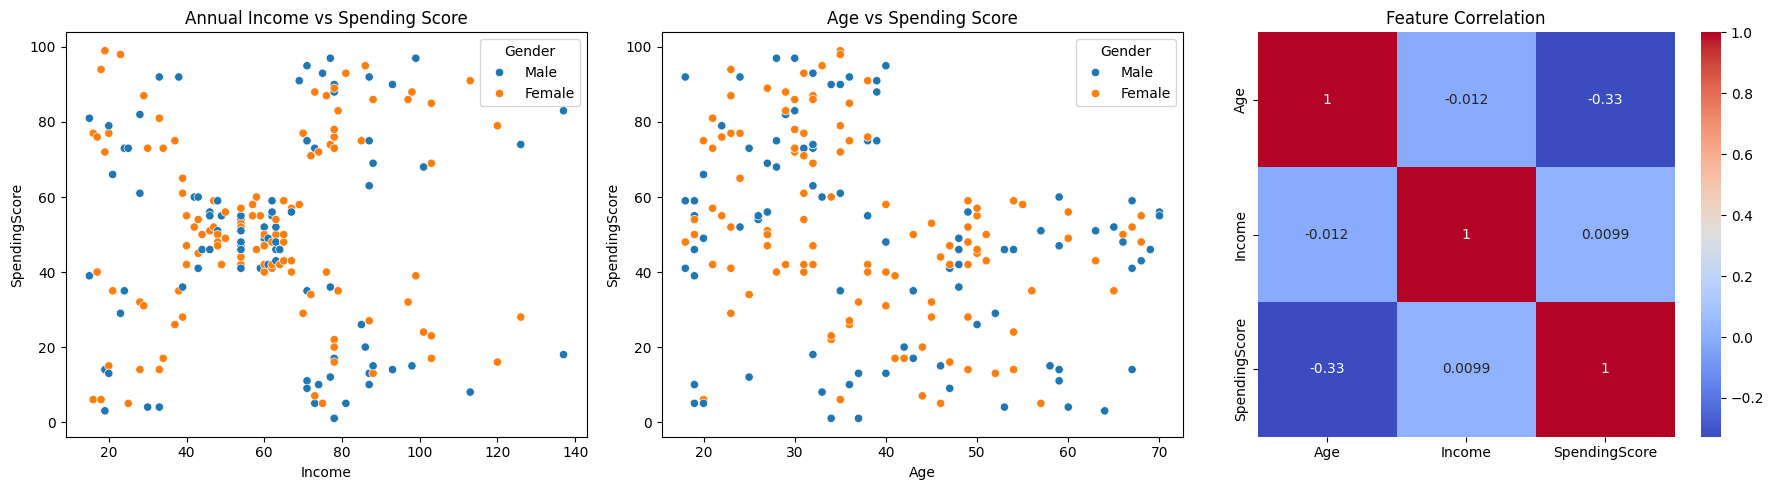

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Income vs Spending Score
sns.scatterplot(
    data=df,
    x="Income",
    y="SpendingScore",
    hue="Gender",
    ax=axes[0]
)
axes[0].set_title("Annual Income vs Spending Score")

# Age vs Spending Score
sns.scatterplot(
    data=df,
    x="Age",
    y="SpendingScore",
    hue="Gender",
    ax=axes[1]
)
axes[1].set_title("Age vs Spending Score")

# Correlation heatmap
sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    ax=axes[2]
)
axes[2].set_title("Feature Correlation")

plt.tight_layout()
plt.show()

In [10]:
FEATURES = ["Income", "SpendingScore"]

X = df[FEATURES].copy()

print("Selected Features:")
display(X.head())

print("\nFeature Shape:", X.shape)

Selected Features:


,Income,SpendingScore
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Feature Shape: (200, 2)


In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

print("\nScaled Data:")
display(pd.DataFrame(
    X_scaled,
    columns=FEATURES
).head())

Feature scaling completed!

Scaled Data:


,Income,SpendingScore
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


In [12]:
results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k,
        "WCSS": model.inertia_,
        "Silhouette Score": silhouette_score(
            X_scaled, labels
        ),
        "Davies-Bouldin Score": davies_bouldin_score(
            X_scaled, labels
        ),
        "Calinski-Harabasz Score": calinski_harabasz_score(
            X_scaled, labels
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,K,WCSS,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,2,269.6910,0.3213,1.2670,95.6694
1,3,157.7040,0.4666,0.7165,151.3351
2,4,108.9213,0.4939,0.7096,174.5952
3,5,65.5684,0.5547,0.5722,248.6493
4,6,55.0573,0.5399,0.6546,243.0879
5,7,44.8648,0.5281,0.7148,254.6212
6,8,37.2282,0.4552,0.7602,267.2790
7,9,32.3923,0.4571,0.7632,270.9484
8,10,29.9819,0.4432,0.7935,260.5403


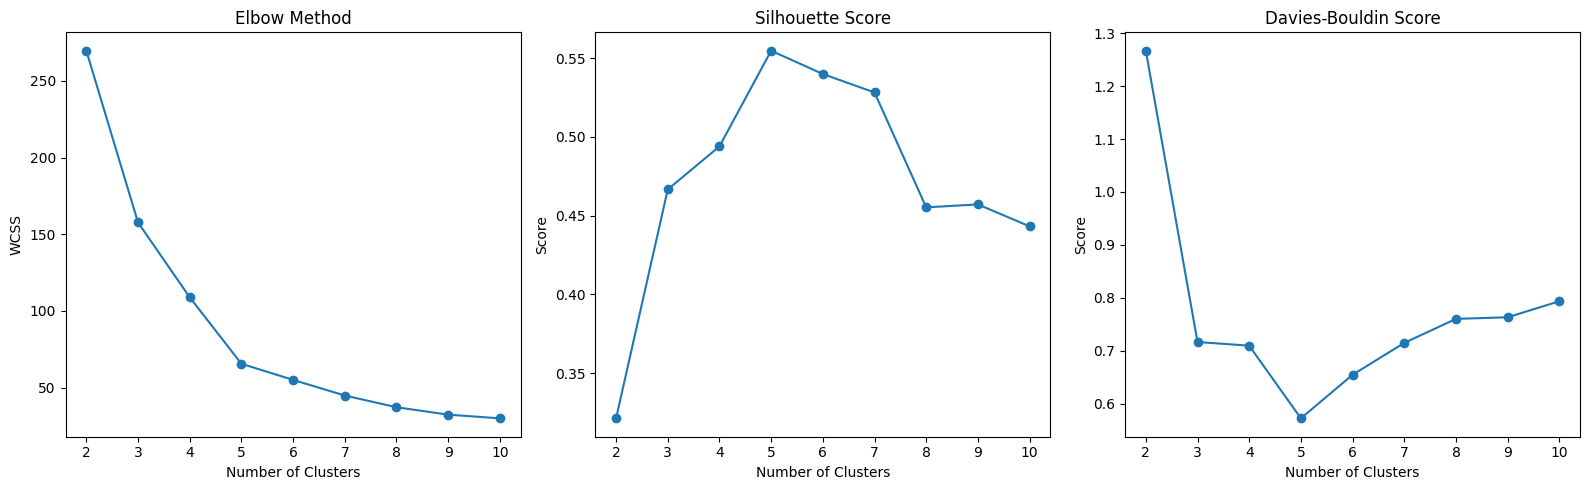

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Elbow Method
axes[0].plot(
    results_df["K"],
    results_df["WCSS"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("WCSS")

# Silhouette Score
axes[1].plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Score")

# Davies-Bouldin Score
axes[2].plot(
    results_df["K"],
    results_df["Davies-Bouldin Score"],
    marker="o"
)
axes[2].set_title("Davies-Bouldin Score")
axes[2].set_xlabel("Number of Clusters")
axes[2].set_ylabel("Score")

plt.tight_layout()
plt.show()

In [14]:
OPTIMAL_K = 5

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    init="k-means++",
    n_init=10,
    random_state=42
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("K-Means model trained successfully!")

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

K-Means model trained successfully!

Cluster Distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


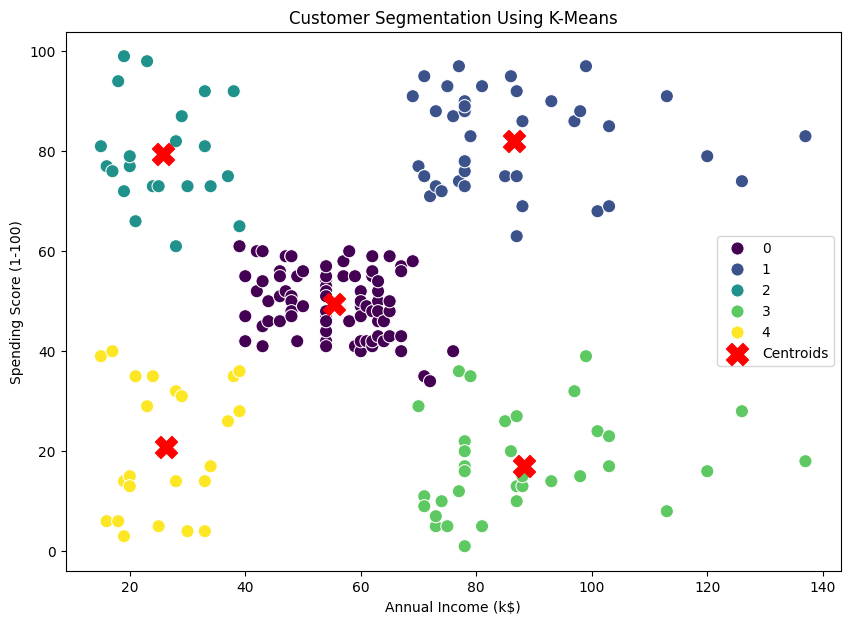

In [15]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Income",
    y="SpendingScore",
    hue="Cluster",
    palette="viridis",
    s=90
)

centres = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.scatter(
    centres[:, 0],
    centres[:, 1],
    marker="X",
    color="red",
    s=250,
    label="Centroids"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [16]:
silhouette = silhouette_score(X_scaled, clusters)

db_score = davies_bouldin_score(X_scaled, clusters)

ch_score = calinski_harabasz_score(X_scaled, clusters)

print("Final Model Evaluation")
print("----------------------")
print(f"Number of Clusters: {OPTIMAL_K}")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Score: {db_score:.4f}")
print(f"Calinski-Harabasz Score: {ch_score:.4f}")

Final Model Evaluation
----------------------
Number of Clusters: 5
Silhouette Score: 0.5547
Davies-Bouldin Score: 0.5722
Calinski-Harabasz Score: 248.6493


In [17]:
PCA_FEATURES = [
    "Age",
    "Income",
    "SpendingScore"
]

X_pca_original = df[PCA_FEATURES].copy()

pca_scaler = StandardScaler()

X_pca_scaled = pca_scaler.fit_transform(
    X_pca_original
)

print("PCA feature scaling completed!")

PCA feature scaling completed!


In [18]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_pca_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Explained Variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Explained Variance Ratio:
[0.44266167 0.33308378]

Total Explained Variance: 77.57 %


In [19]:
kmeans_pca = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init=10,
    random_state=42
)

clusters_pca = kmeans_pca.fit_predict(pca_data)

df["PCA_Cluster"] = clusters_pca

print("K-Means on PCA data completed!")

K-Means on PCA data completed!


In [20]:
pca_silhouette = silhouette_score(
    pca_data,
    clusters_pca
)

pca_db = davies_bouldin_score(
    pca_data,
    clusters_pca
)

print("PCA Model Evaluation")
print("--------------------")
print(f"Silhouette Score: {pca_silhouette:.4f}")
print(f"Davies-Bouldin Score: {pca_db:.4f}")

PCA Model Evaluation
--------------------
Silhouette Score: 0.3931
Davies-Bouldin Score: 0.8045


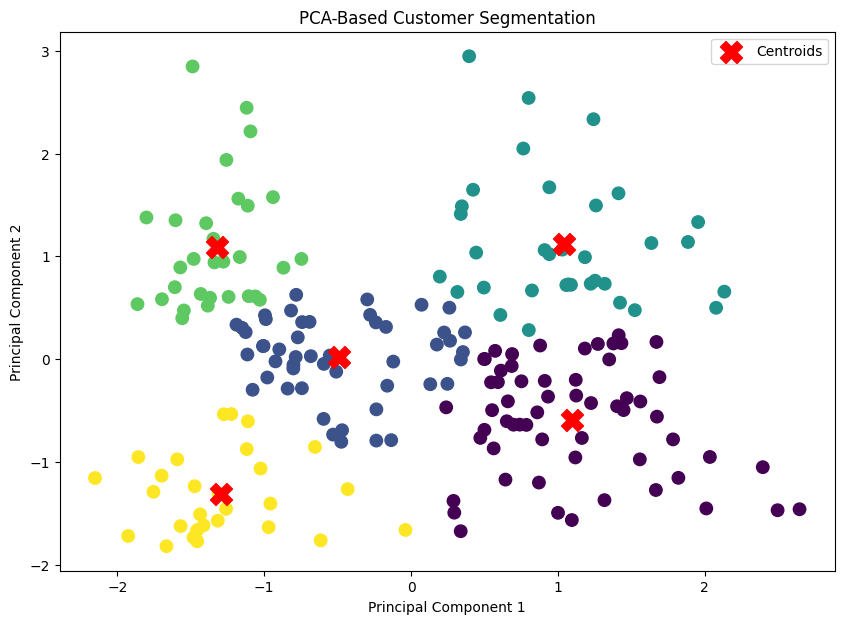

In [21]:
plt.figure(figsize=(10, 7))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=clusters_pca,
    cmap="viridis",
    s=80
)

plt.scatter(
    kmeans_pca.cluster_centers_[:, 0],
    kmeans_pca.cluster_centers_[:, 1],
    marker="X",
    color="red",
    s=250,
    label="Centroids"
)

plt.title("PCA-Based Customer Segmentation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

In [22]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Income", "mean"),
    Average_Spending=("SpendingScore", "mean")
).round(2)

display(cluster_profile)

,Customer_Count,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


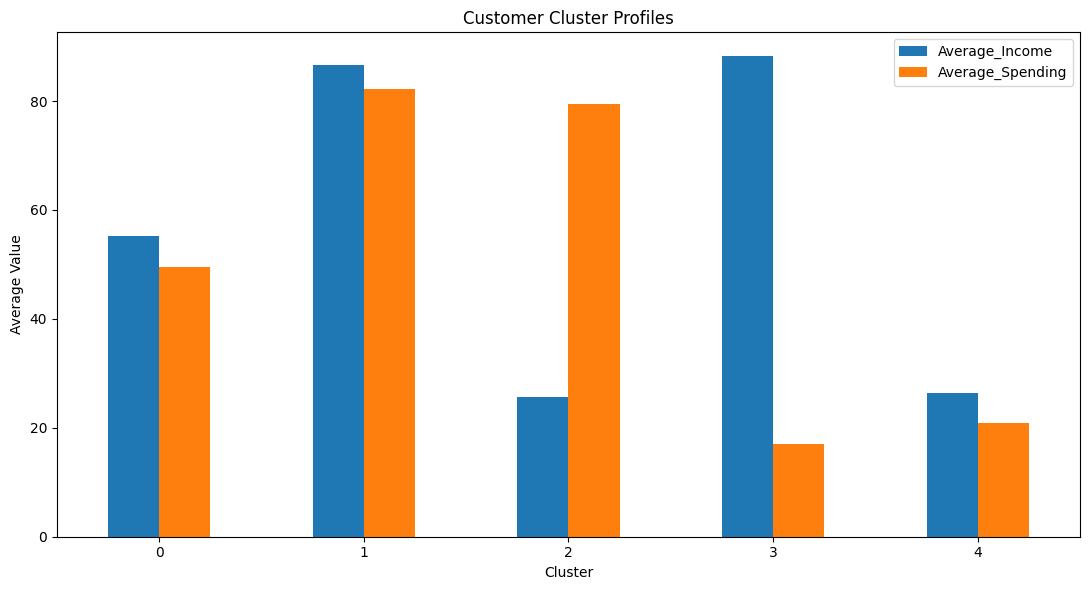

In [23]:
cluster_profile[[
    "Average_Income",
    "Average_Spending"
]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Customer Cluster Profiles")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

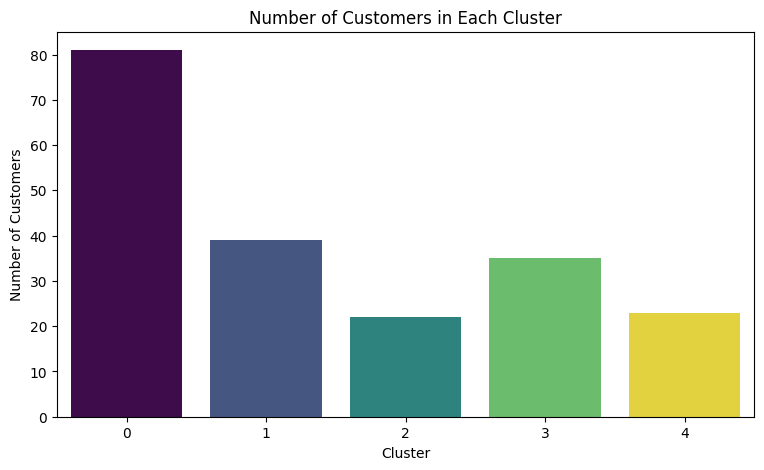

In [24]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

In [25]:
gender_profile = pd.crosstab(
    df["Cluster"],
    df["Gender"]
)

display(gender_profile)

Gender,Female,Male
Cluster,,
0,48,33
1,21,18
2,13,9
3,16,19
4,14,9


In [26]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save trained model
joblib.dump(kmeans, "models/kmeans_model.pkl")

# Save scaler
joblib.dump(scaler, "models/scaler.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")

Model saved successfully!
Scaler saved successfully!


In [27]:
import json

model_info = {
    "model_name": "KMeans Customer Segmentation",
    "model_version": "1.0",
    "algorithm": "KMeans",
    "optimal_clusters": 5,
    "features": FEATURES,
    "silhouette_score": round(silhouette, 4),
    "davies_bouldin_score": round(db_score, 4),
    "random_state": 42
}

with open("models/model_metadata.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model metadata saved!")
print(json.dumps(model_info, indent=4))

Model metadata saved!
{
    "model_name": "KMeans Customer Segmentation",
    "model_version": "1.0",
    "algorithm": "KMeans",
    "optimal_clusters": 5,
    "features": [
        "Income",
        "SpendingScore"
    ],
    "silhouette_score": 0.5547,
    "davies_bouldin_score": 0.5722,
    "random_state": 42
}


In [28]:
os.makedirs("outputs", exist_ok=True)

df.to_csv(
    "outputs/customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/cluster_profiles.csv"
)

print("Customer segmentation results exported!")

Customer segmentation results exported!


In [29]:
print("Saved Model Files:")

for folder in ["models", "outputs"]:
    print(f"\n{folder}/")

    for file in os.listdir(folder):
        print("  ", file)

Saved Model Files:

models/
   kmeans_model.pkl
   model_metadata.json
   scaler.pkl

outputs/
   customer_segments.csv
   cluster_profiles.csv


In [30]:
import shutil

# Create a ZIP containing all model files and outputs
shutil.make_archive(
    "customer_segmentation_project",
    "zip",
    ".",
    "models"
)

print("Model files packaged successfully!")

Model files packaged successfully!


In [31]:
from google.colab import files

files.download("customer_segmentation_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import files

files.download("outputs/customer_segments.csv")
files.download("outputs/cluster_profiles.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>